In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ---------------- CONFIG ----------------
COUNTRY = "Zambia"          # "India" or "Zambia"
SPIKE_THR = 0.10           # primary spike: next-month rise > 10%
SEVERE_THR = 0.15          # sensitivity check: rise > 15%

MODEL_COMMODITIES = {
    "India":  ["Onions", "Potatoes", "Tomatoes"],
    "Zambia": ["Maize (white)"],
}
# ----------------------------------------

df = pd.read_csv(f"clean_monthly_{COUNTRY.lower()}.csv", parse_dates=["date"])
df = df[df["commodity"].isin(MODEL_COMMODITIES[COUNTRY])]
df = df.sort_values(["commodity", "date"]).reset_index(drop=True)

assert df["price"].notna().all(), "Fix remaining gaps in notebook 1 first"
print(df["commodity"].value_counts())

commodity
Maize (white)    210
Name: count, dtype: int64


In [9]:
def build_features(g):
    """All features at month t use data up to and including t only.
    Targets look one month ahead (t+1)."""
    g = g.sort_values("date").copy()
    p = g["price"]

    # current and lagged month-over-month changes
    g["mom"] = p.pct_change()
    for k in [1, 2, 3, 6, 12]:
        g[f"mom_lag{k}"] = g["mom"].shift(k)

    # momentum over longer windows
    for k in [3, 6, 12]:
        g[f"chg_{k}m"] = p.pct_change(k)

    # price relative to its recent average (level-free)
    for k in [3, 6, 12]:
        g[f"p_to_ma{k}"] = p / p.rolling(k).mean()

    # recent volatility
    for k in [3, 6, 12]:
        g[f"vol_{k}m"] = g["mom"].rolling(k).std()

    # seasonality (cyclical encoding of month)
    g["month_sin"] = np.sin(2 * np.pi * g["date"].dt.month / 12)
    g["month_cos"] = np.cos(2 * np.pi * g["date"].dt.month / 12)

    # recent spike history
    is_spike = (g["mom"] > SPIKE_THR).astype(int)
    g["spike_now"] = is_spike
    g["spikes_last6"] = is_spike.rolling(6).sum()
    g["spikes_last12"] = is_spike.rolling(12).sum()

    # ---- targets (t+1) ----
    g["next_price"] = p.shift(-1)
    g["next_mom"] = g["mom"].shift(-1)
    valid = g["next_mom"].notna()
    g["spike_next"] = np.where(valid, (g["next_mom"] > SPIKE_THR).astype(float), np.nan)
    g["spike_next_severe"] = np.where(valid, (g["next_mom"] > SEVERE_THR).astype(float), np.nan)
    return g

In [10]:
parts = [build_features(g) for _, g in df.groupby("commodity")]
full = pd.concat(parts, ignore_index=True)

ID_COLS = ["date", "country", "commodity", "currency", "n_markets", "was_filled"]
TARGET_COLS = ["next_price", "next_mom", "spike_next", "spike_next_severe"]
FEATURES = [c for c in full.columns
            if c not in ID_COLS + TARGET_COLS + ["price"]]

# drop warm-up rows (lags need up to 12 months) and the last row (no t+1)
data = full.dropna(subset=FEATURES + TARGET_COLS).copy()
data[["spike_next", "spike_next_severe"]] = data[["spike_next", "spike_next_severe"]].astype(int)

print(f"Rows: {len(full)} -> {len(data)} after dropping warm-up and last month")
print(f"{len(FEATURES)} features:", FEATURES)

Rows: 210 -> 196 after dropping warm-up and last month
20 features: ['mom', 'mom_lag1', 'mom_lag2', 'mom_lag3', 'mom_lag6', 'mom_lag12', 'chg_3m', 'chg_6m', 'chg_12m', 'p_to_ma3', 'p_to_ma6', 'p_to_ma12', 'vol_3m', 'vol_6m', 'vol_12m', 'month_sin', 'month_cos', 'spike_now', 'spikes_last6', 'spikes_last12']


In [11]:
# Rebuild features using only data up to a cutoff and confirm the feature row
# at the cutoff is identical to the one from the full dataset.
for com in df["commodity"].unique():
    g = df[df["commodity"] == com].sort_values("date").reset_index(drop=True)
    cut = int(len(g) * 0.6)
    trunc = build_features(g.iloc[: cut + 1])
    full_row = build_features(g).iloc[cut]
    same = np.allclose(trunc.iloc[-1][FEATURES].astype(float).values,
                       full_row[FEATURES].astype(float).values, equal_nan=True)
    print(f"{com}: features use only past data -> {same}")

Maize (white): features use only past data -> True


In [12]:
bal = data.groupby("commodity").agg(
    rows=("spike_next", "size"),
    first=("date", "min"),
    last=("date", "max"),
    spikes_10=("spike_next", "sum"),
    spikes_15=("spike_next_severe", "sum"),
)
bal["pct_10"] = (bal["spikes_10"] / bal["rows"] * 100).round(1)
bal["pct_15"] = (bal["spikes_15"] / bal["rows"] * 100).round(1)
bal

,rows,first,last,spikes_10,spikes_15,pct_10,pct_15
commodity,,,,,,,
Maize (white),196,2004-02-01,2020-05-01,31,9,15.8,4.6


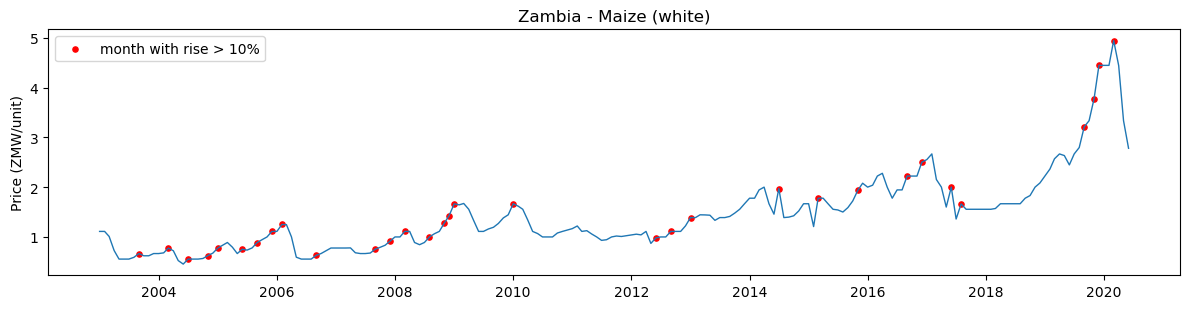

In [13]:
coms = data["commodity"].unique()
fig, axes = plt.subplots(len(coms), 1, figsize=(12, 3.2 * len(coms)))
axes = np.atleast_1d(axes)

for ax, com in zip(axes, coms):
    s = full[full["commodity"] == com]
    ax.plot(s["date"], s["price"], lw=1)
    sp = s[s["mom"] > SPIKE_THR]
    ax.scatter(sp["date"], sp["price"], color="red", s=14,
               label=f"month with rise > {int(SPIKE_THR*100)}%")
    ax.set_title(f"{COUNTRY} - {com}")
    ax.set_ylabel(f"Price ({full['currency'].iloc[0]}/unit)")
    ax.legend(loc="upper left")

plt.tight_layout()
plt.show()

In [14]:
out_path = f"features_{COUNTRY.lower()}.csv"
data.to_csv(out_path, index=False)
print("Saved", out_path, data.shape)

Saved features_zambia.csv (196, 31)
